# Brain MRI Classification on Google Colab

Notebook nay duoc chinh lai theo phong cach ro rang hon, gan voi notebook CT classification:
- co ghi chu truoc tung cell
- co preview du lieu
- co training curves, confusion matrix, sample predictions
- luu model va cac anh output vao Google Drive de dung cho giao dien

## Cell 1 - Import, Config, Path Setup

Cell nay lam cac viec chinh:
- import thu vien can thiet cho classification bang PyTorch
- khai bao tham so train va preprocess
- mount Google Drive neu chay tren Colab
- khai bao duong dan dataset va noi luu artifact

Ban thuong chi can sua 2 cho:
- `DATASET_ROOT`: noi dat bo du lieu MRI
- `ARTIFACTS_ROOT`: noi luu model, report va cac anh output

Khuyen nghi:
- de dataset o `/content/...` de train nhanh hon neu ban da copy sang runtime
- de artifact o `/content/drive/...` de khong bi mat khi Colab reset runtime

In [ ]:
import copy
import json
import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models

SEED = 42
BATCH_SIZE = 32
EPOCHS = 8
LEARNING_RATE = 1e-4
IMAGE_SIZE = (224, 224)
NUM_WORKERS = 2
LOG_EVERY = 10

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
SUPPORTED_SUFFIXES = {'.jpg', '.jpeg', '.png'}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Running on: {device}')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print('google.colab not available. If you run locally, update paths manually.')

DRIVE_ROOT = Path('/content/drive/MyDrive/ResourceDACN3') if IN_COLAB else Path.cwd()
DATASET_ROOT = Path('/content/Dataset_MRI') if IN_COLAB else DRIVE_ROOT / 'Dataset_MRI'
ARTIFACTS_ROOT = DRIVE_ROOT / 'artifacts'
ARTIFACTS_ROOT.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = ARTIFACTS_ROOT / 'brain_mri_alexnet_best.pth'
FINAL_MODEL_PATH = ARTIFACTS_ROOT / 'brain_mri_alexnet_final.pth'
LABEL_MAP_PATH = ARTIFACTS_ROOT / 'brain_mri_labels.json'
HISTORY_PATH = ARTIFACTS_ROOT / 'brain_mri_training_history.json'
REPORT_PATH = ARTIFACTS_ROOT / 'brain_mri_classification_report.json'
CONFUSION_MATRIX_PATH = ARTIFACTS_ROOT / 'brain_mri_confusion_matrix.png'
CURVES_PATH = ARTIFACTS_ROOT / 'brain_mri_training_curves.png'
SAMPLE_GRID_PATH = ARTIFACTS_ROOT / 'brain_mri_sample_grid.png'
PREDICTIONS_PATH = ARTIFACTS_ROOT / 'brain_mri_sample_predictions.png'

print(f'Dataset root: {DATASET_ROOT}')
print(f'Artifacts root: {ARTIFACTS_ROOT}')
print('Neu dataset cua ban dang nam tren Google Drive, ban co the copy sang /content de train nhanh hon.')
print("Vi du: !cp -r /content/drive/MyDrive/ResourceDACN3/Dataset_MRI /content/")

Running on: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset root: /content/Dataset_MRI
Artifacts root: /content/drive/MyDrive/ResourceDACN3/artifacts
Neu dataset cua ban dang nam tren Google Drive, ban co the copy sang /content de train nhanh hon.
Vi du: !cp -r /content/drive/MyDrive/ResourceDACN3/Dataset_MRI /content/


In [ ]:
!cp -r /content/drive/MyDrive/ResourceDACN3/Dataset_MRI /content/

## Cell 2 - Thu Thap Du Lieu Va Kiem Tra Phan Bo Lop

Cell nay quet dataset theo ten thu muc lop va tao bang du lieu `df_all` gom 2 cot:
- `image_path`: duong dan toi anh
- `label`: nhan lop cua anh

Cell nay giup ban kiem tra:
- co doc duoc dataset hay khong
- moi lop co bao nhieu anh
- mot vai dong du lieu dau vao co dung nhan hay khong

In [ ]:
def collect_mri_samples(dataset_root: Path) -> pd.DataFrame:
    records = []

    for image_path in sorted(dataset_root.rglob('*')):
        if image_path.suffix.lower() in SUPPORTED_SUFFIXES:
            records.append({
                'image_path': str(image_path),
                'label': image_path.parent.name,
            })

    df = pd.DataFrame(records)
    if df.empty:
        raise FileNotFoundError(
            f'Khong tim thay anh nao trong {dataset_root}. Hay kiem tra lai DATASET_ROOT.'
        )

    return df


df_all = collect_mri_samples(DATASET_ROOT)
class_names = sorted(df_all['label'].unique())
class_to_idx = {class_name: idx for idx, class_name in enumerate(class_names)}
idx_to_class = {idx: class_name for class_name, idx in class_to_idx.items()}

with open(LABEL_MAP_PATH, 'w', encoding='utf-8') as f:
    json.dump(
        {
            'class_to_idx': class_to_idx,
            'idx_to_class': idx_to_class,
            'image_size': list(IMAGE_SIZE),
            'mean': IMAGENET_MEAN.tolist(),
            'std': IMAGENET_STD.tolist(),
            'model_name': 'alexnet',
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

print(f'Total images: {len(df_all)}')
print(df_all['label'].value_counts())
print('Label map saved to:', LABEL_MAP_PATH)
display(df_all.head())

Total images: 7200
label
glioma        1800
meningioma    1800
notumor       1800
pituitary     1800
Name: count, dtype: int64
Label map saved to: /content/drive/MyDrive/ResourceDACN3/artifacts/brain_mri_labels.json


,image_path,label
0,/content/Dataset_MRI/Testing/glioma/Te-gl_1.jpg,glioma
1,/content/Dataset_MRI/Testing/glioma/Te-gl_10.jpg,glioma
2,/content/Dataset_MRI/Testing/glioma/Te-gl_100.jpg,glioma
3,/content/Dataset_MRI/Testing/glioma/Te-gl_101.jpg,glioma
4,/content/Dataset_MRI/Testing/glioma/Te-gl_102.jpg,glioma


## Cell 3 - Hien Thi Mot So Anh Mau

Cell nay hien thi mot vai anh MRI goc theo tung lop de ban kiem tra nhanh:
- anh co doc dung khong
- thu muc lop co hop ly khong
- bo du lieu co van de gi de nhan thay som

Anh preview se duoc luu vao thu muc artifact.

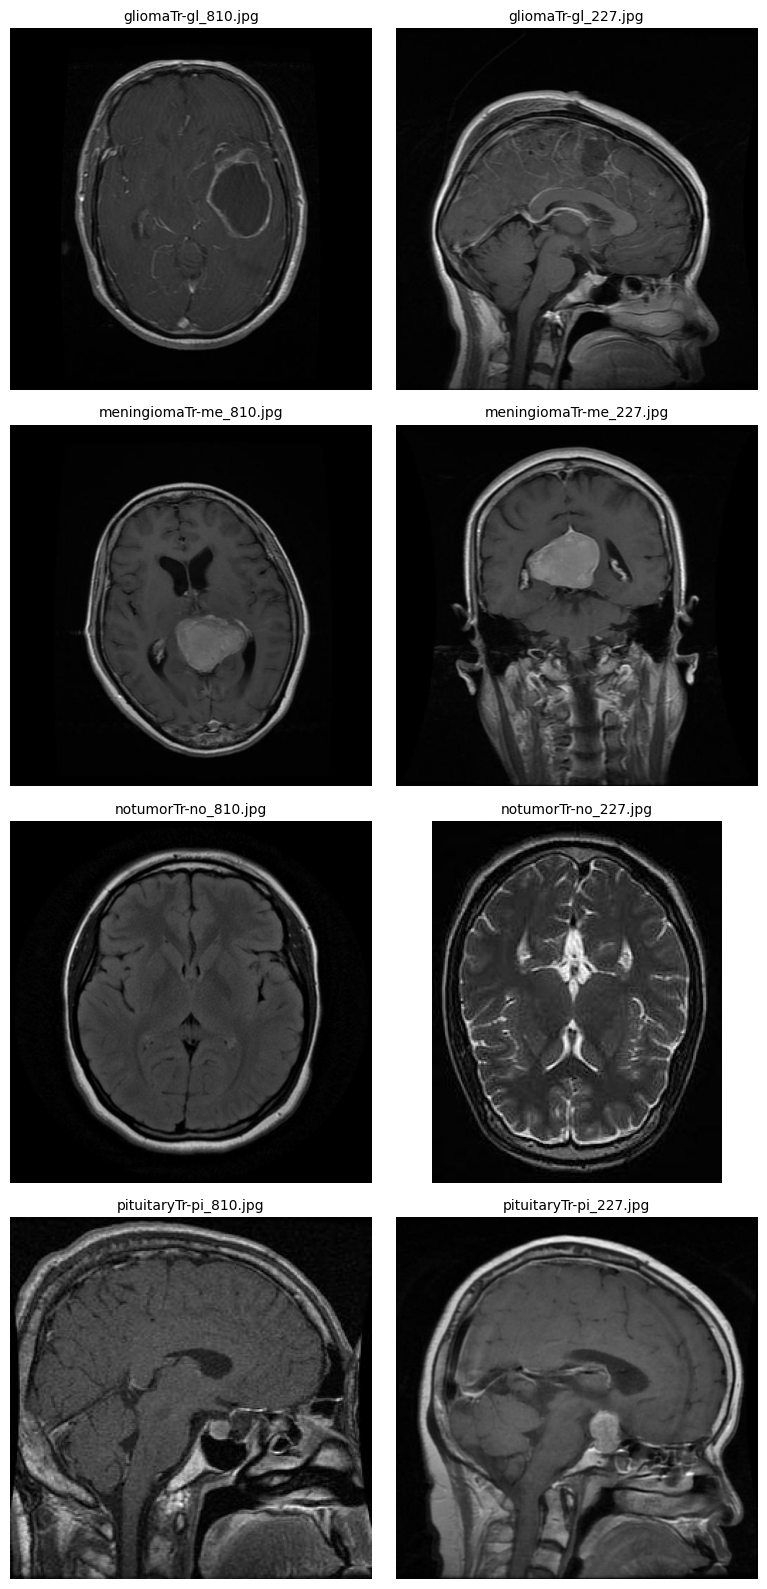

Sample grid saved to: /content/drive/MyDrive/ResourceDACN3/artifacts/brain_mri_sample_grid.png


In [ ]:
def visualize_samples(df: pd.DataFrame, n_per_class: int = 2):
    classes = sorted(df['label'].unique())
    rows = len(classes)
    cols = n_per_class
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))

    if rows == 1 and cols == 1:
        axes = np.array([[axes]])
    elif rows == 1:
        axes = np.array([axes])
    elif cols == 1:
        axes = np.array([[ax] for ax in axes])

    for row_idx, label in enumerate(classes):
        subset = df[df['label'] == label].sample(min(n_per_class, len(df[df['label'] == label])), random_state=SEED)
        for col_idx in range(cols):
            ax = axes[row_idx, col_idx]
            ax.axis('off')
            if col_idx < len(subset):
                image_path = subset.iloc[col_idx]['image_path']
                image = cv2.imread(image_path, cv2.IMREAD_COLOR)
                image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
                ax.imshow(image, cmap='gray')
                ax.set_title(f'{label}{Path(image_path).name}', fontsize=10)

    plt.tight_layout()
    plt.savefig(SAMPLE_GRID_PATH, dpi=120, bbox_inches='tight')
    plt.show()
    print(f'Sample grid saved to: {SAMPLE_GRID_PATH}')


visualize_samples(df_all, n_per_class=2)

## Cell 4 - Chia Train, Validation, Test

Cell nay chia du lieu theo ti le:
- `80%` train
- `10%` validation
- `10%` test

Diem quan trong:
- su dung `stratify` theo `label` de giu ti le cac lop dong deu
- luu `class_to_idx` va `idx_to_class` de infer dung thu tu nhan

In [ ]:
train_df, temp_df = train_test_split(
    df_all,
    test_size=0.2,
    random_state=SEED,
    stratify=df_all['label'],
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=SEED,
    stratify=temp_df['label'],
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')
display(pd.DataFrame({
    'train': train_df['label'].value_counts().reindex(class_names, fill_value=0),
    'val': val_df['label'].value_counts().reindex(class_names, fill_value=0),
    'test': test_df['label'].value_counts().reindex(class_names, fill_value=0),
}))

Train: 5760 | Val: 720 | Test: 720


,train,val,test
label,,,
glioma,1440,180,180
meningioma,1440,180,180
notumor,1440,180,180
pituitary,1440,180,180


## Cell 5 - Tao Dataset Va DataLoader

Cell nay chuyen `DataFrame` thanh du lieu cho PyTorch.

No se:
- doc anh bang OpenCV
- resize ve `224x224`
- augment nhe cho tap train
- normalize theo ImageNet
- doi ve tensor dang `(C, H, W)`

Neu cell nay chay duoc, ban se thay shape batch mau nhu `torch.Size([32, 3, 224, 224])`.

In [ ]:
class BrainMRIDataset(Dataset):
    def __init__(self, dataframe, class_to_idx, image_size=(224, 224), augment=False):
        self.df = dataframe.reset_index(drop=True).copy()
        self.class_to_idx = class_to_idx
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def _augment_image(self, image):
        if random.random() < 0.5:
            image = cv2.flip(image, 1)
        if random.random() < 0.2:
            angle = random.uniform(-10, 10)
            h, w = image.shape[:2]
            matrix = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
            image = cv2.warpAffine(
                image,
                matrix,
                (w, h),
                flags=cv2.INTER_LINEAR,
                borderMode=cv2.BORDER_REFLECT_101,
            )
        return image

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_path = row['image_path']
        image = cv2.imread(image_path, cv2.IMREAD_COLOR)
        if image is None:
            raise ValueError(f'Could not read image: {image_path}')

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, self.image_size)

        if self.augment:
            image = self._augment_image(image)

        image = image.astype(np.float32) / 255.0
        image = (image - IMAGENET_MEAN) / IMAGENET_STD
        image = np.transpose(image, (2, 0, 1))

        label = self.class_to_idx[row['label']]
        return torch.from_numpy(image).float(), torch.tensor(label).long()


train_ds = BrainMRIDataset(train_df, class_to_idx, image_size=IMAGE_SIZE, augment=True)
val_ds = BrainMRIDataset(val_df, class_to_idx, image_size=IMAGE_SIZE, augment=False)
test_ds = BrainMRIDataset(test_df, class_to_idx, image_size=IMAGE_SIZE, augment=False)

loader_kwargs = {
    'batch_size': BATCH_SIZE,
    'num_workers': NUM_WORKERS,
    'pin_memory': torch.cuda.is_available(),
}

train_loader = DataLoader(train_ds, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_ds, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kwargs)

images_sample, labels_sample = next(iter(train_loader))
print(f'Image batch shape: {images_sample.shape}')
print(f'Label batch shape: {labels_sample.shape}')
print(f'Train steps: {len(train_loader)} | Val steps: {len(val_loader)} | Test steps: {len(test_loader)}')

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Train steps: 180 | Val steps: 23 | Test steps: 23


## Cell 6 - Khoi Tao Model Classification

Cell nay xay dung model `AlexNet` pretrained, giu logic gan voi notebook MRI goc cua ban.

Classifier cuoi duoc doi lai theo so lop cua dataset MRI.
Neu Colab khong tai duoc pretrained weights, notebook se tu fallback sang `weights=None`.

In [ ]:
class MedicalAlexNet(nn.Module):
    def __init__(self, num_classes, use_pretrained=True):
        super().__init__()
        weights = models.AlexNet_Weights.DEFAULT if use_pretrained else None
        try:
            self.model = models.alexnet(weights=weights)
        except Exception as exc:
            print(f'Khong tai duoc pretrained weights: {exc}')
            print('Se khoi tao AlexNet voi weights=None')
            self.model = models.alexnet(weights=None)

        self.model.classifier = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Linear(4096, num_classes),
        )

    def forward(self, x):
        return self.model(x)


model = MedicalAlexNet(num_classes=len(class_names), use_pretrained=True).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 132MB/s]


## Cell 7 - Train Va Luu Checkpoint

Day la cell train chinh.

Cell nay se:
- train model theo tung epoch
- in log theo batch de theo doi tien do
- tinh `train_acc` va `val_acc`
- luu `best model` moi khi `val_acc` tang
- luu `final model` va `training_history.json` khi train xong

In [ ]:
history = []
best_val_acc = 0.0
best_state_dict = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch_idx, (images, labels) in enumerate(train_loader, start=1):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        preds = outputs.argmax(dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

        if batch_idx % LOG_EVERY == 0 or batch_idx == len(train_loader):
            avg_loss_so_far = running_loss / batch_idx
            train_acc_so_far = 100.0 * train_correct / train_total
            print(
                f'Epoch {epoch + 1}/{EPOCHS} | Batch {batch_idx}/{len(train_loader)} | '
                f'Avg Loss: {avg_loss_so_far:.4f} | Train Acc: {train_acc_so_far:.2f}%'
            )

    train_loss = running_loss / len(train_loader)
    train_acc = 100.0 * train_correct / train_total

    model.eval()
    val_correct = 0
    val_total = 0
    val_loss_sum = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(images)
            loss = criterion(outputs, labels)
            preds = outputs.argmax(dim=1)

            val_loss_sum += loss.item()
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / len(val_loader)
    val_acc = 100.0 * val_correct / val_total

    history.append({
        'epoch': epoch + 1,
        'train_loss': train_loss,
        'train_acc': train_acc,
        'val_loss': val_loss,
        'val_acc': val_acc,
    })

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state_dict = copy.deepcopy(model.state_dict())
        torch.save(
            {
                'model_state_dict': best_state_dict,
                'class_to_idx': class_to_idx,
                'idx_to_class': idx_to_class,
                'image_size': list(IMAGE_SIZE),
                'mean': IMAGENET_MEAN.tolist(),
                'std': IMAGENET_STD.tolist(),
                'model_name': 'alexnet',
                'best_val_acc': best_val_acc,
            },
            BEST_MODEL_PATH,
        )
        print(f'Saved new best model at epoch {epoch + 1} with val acc {val_acc:.2f}%')

    print(
        f'Epoch {epoch + 1}/{EPOCHS} completed - '
        f'Train Loss: {train_loss:.4f} - Train Acc: {train_acc:.2f}% - '
        f'Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.2f}%'
    )

model.load_state_dict(best_state_dict)
torch.save(
    {
        'model_state_dict': model.state_dict(),
        'class_to_idx': class_to_idx,
        'idx_to_class': idx_to_class,
        'image_size': list(IMAGE_SIZE),
        'mean': IMAGENET_MEAN.tolist(),
        'std': IMAGENET_STD.tolist(),
        'model_name': 'alexnet',
        'best_val_acc': best_val_acc,
    },
    FINAL_MODEL_PATH,
)

with open(HISTORY_PATH, 'w', encoding='utf-8') as f:
    json.dump(history, f, ensure_ascii=False, indent=2)

print(f'Best validation accuracy: {best_val_acc:.2f}%')
print(f'Best checkpoint saved to: {BEST_MODEL_PATH}')
print(f'Final checkpoint saved to: {FINAL_MODEL_PATH}')
print(f'Training history saved to: {HISTORY_PATH}')

Epoch 1/8 | Batch 10/180 | Avg Loss: 1.1433 | Train Acc: 55.00%
Epoch 1/8 | Batch 20/180 | Avg Loss: 0.9729 | Train Acc: 63.12%
Epoch 1/8 | Batch 30/180 | Avg Loss: 0.8630 | Train Acc: 67.29%
Epoch 1/8 | Batch 40/180 | Avg Loss: 0.7712 | Train Acc: 70.70%
Epoch 1/8 | Batch 50/180 | Avg Loss: 0.6935 | Train Acc: 73.56%
Epoch 1/8 | Batch 60/180 | Avg Loss: 0.6430 | Train Acc: 76.15%
Epoch 1/8 | Batch 70/180 | Avg Loss: 0.6186 | Train Acc: 77.05%
Epoch 1/8 | Batch 80/180 | Avg Loss: 0.5876 | Train Acc: 78.28%
Epoch 1/8 | Batch 90/180 | Avg Loss: 0.5548 | Train Acc: 79.65%
Epoch 1/8 | Batch 100/180 | Avg Loss: 0.5343 | Train Acc: 80.56%
Epoch 1/8 | Batch 110/180 | Avg Loss: 0.5143 | Train Acc: 81.28%
Epoch 1/8 | Batch 120/180 | Avg Loss: 0.5038 | Train Acc: 81.46%
Epoch 1/8 | Batch 130/180 | Avg Loss: 0.4884 | Train Acc: 82.09%
Epoch 1/8 | Batch 140/180 | Avg Loss: 0.4736 | Train Acc: 82.54%
Epoch 1/8 | Batch 150/180 | Avg Loss: 0.4595 | Train Acc: 83.04%
Epoch 1/8 | Batch 160/180 | Avg Lo

## Cell 8 - Ve Training Curves

Cell nay ve 2 bieu do:
- loss train/validation
- accuracy train/validation

Muc dich la de quan sat model co hoc duoc khong va co dau hieu overfitting hay khong. Anh se duoc luu vao thu muc artifact.

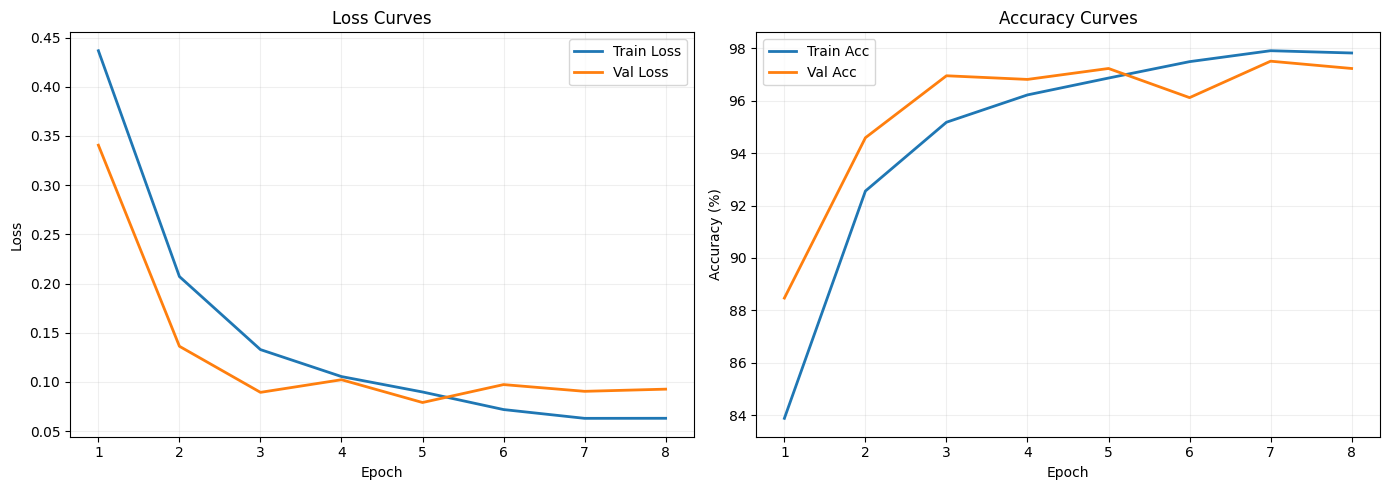

Training curves saved to: /content/drive/MyDrive/ResourceDACN3/artifacts/brain_mri_training_curves.png


In [ ]:
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_df['epoch'], history_df['train_loss'], label='Train Loss', linewidth=2)
axes[0].plot(history_df['epoch'], history_df['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_title('Loss Curves')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(history_df['epoch'], history_df['train_acc'], label='Train Acc', linewidth=2)
axes[1].plot(history_df['epoch'], history_df['val_acc'], label='Val Acc', linewidth=2)
axes[1].set_title('Accuracy Curves')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.savefig(CURVES_PATH, dpi=120, bbox_inches='tight')
plt.show()
print(f'Training curves saved to: {CURVES_PATH}')

## Cell 9 - Danh Gia Tren Test Set

Cell nay danh gia model tot nhat tren tap test va tao 2 output quan trong:
- `classification_report`
- `confusion_matrix`

Ca hai deu duoc luu vao thu muc artifact de ban dung lai sau nay.


Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      0.94      0.97       180
  meningioma       0.95      0.97      0.96       180
     notumor       0.98      0.98      0.98       180
   pituitary       0.97      0.99      0.98       180

    accuracy                           0.97       720
   macro avg       0.97      0.97      0.97       720
weighted avg       0.97      0.97      0.97       720



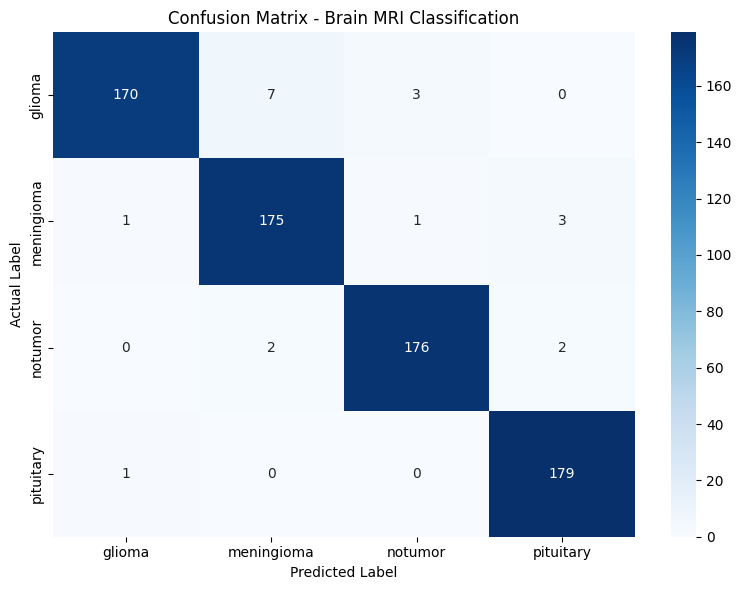

Classification report saved to: /content/drive/MyDrive/ResourceDACN3/artifacts/brain_mri_classification_report.json
Confusion matrix saved to: /content/drive/MyDrive/ResourceDACN3/artifacts/brain_mri_confusion_matrix.png


In [ ]:
model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(images)
        preds = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

report_text = classification_report(y_true, y_pred, target_names=class_names)
report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)

print('\nClassification Report:')
print(report_text)

with open(REPORT_PATH, 'w', encoding='utf-8') as f:
    json.dump(report_dict, f, ensure_ascii=False, indent=2)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Brain MRI Classification')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig(CONFUSION_MATRIX_PATH, dpi=120, bbox_inches='tight')
plt.show()

print(f'Classification report saved to: {REPORT_PATH}')
print(f'Confusion matrix saved to: {CONFUSION_MATRIX_PATH}')

## Cell 10 - Hien Thi Mot So Du Doan Mau

Cell nay lay mot vai anh tu tap test, dua vao model va hien thi:
- anh goc
- nhan that
- nhan du doan
- do tin cay

Anh tong hop se duoc luu vao thu muc artifact.

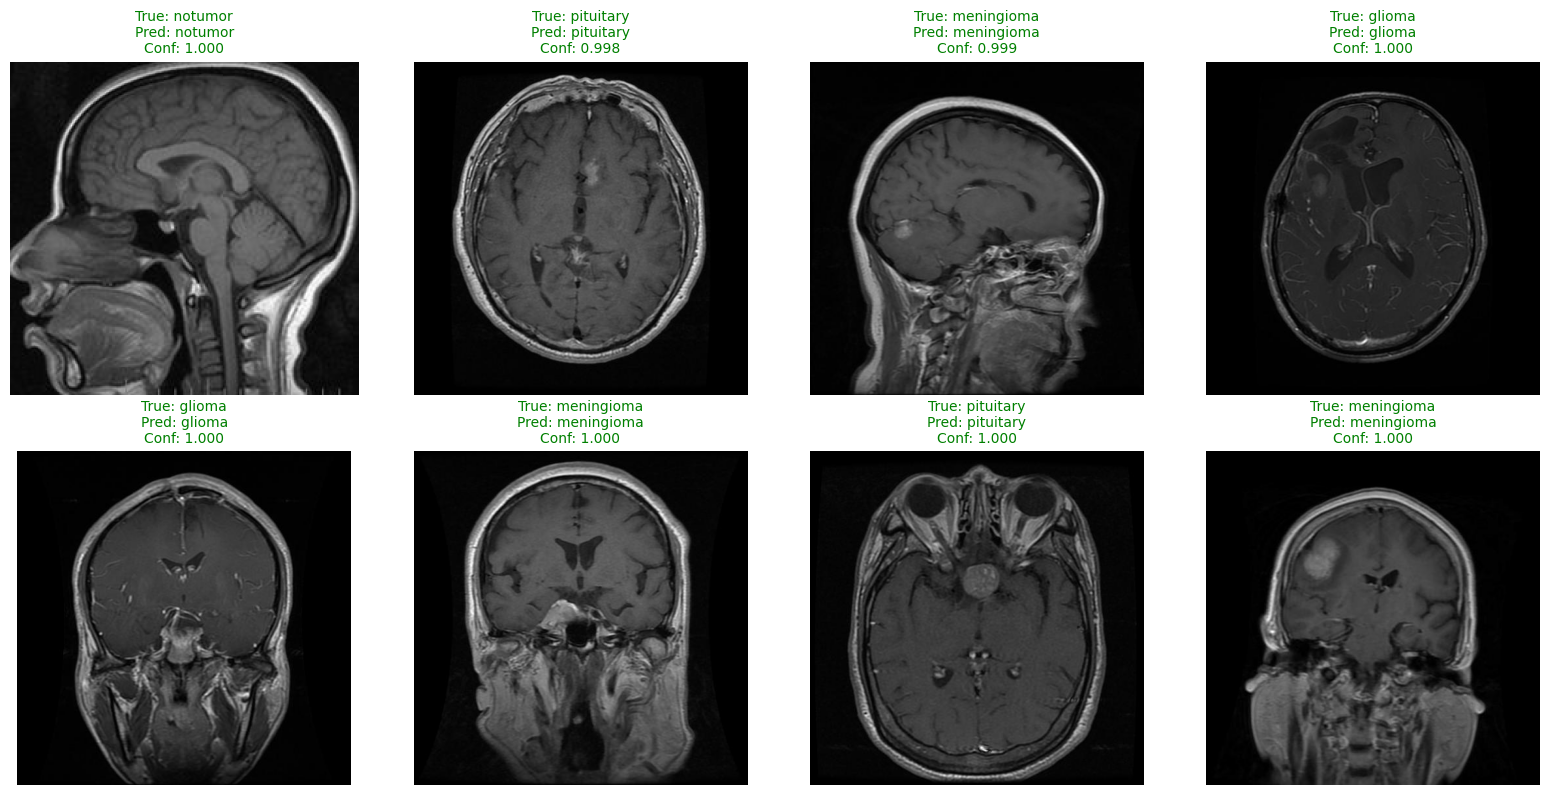

Sample predictions saved to: /content/drive/MyDrive/ResourceDACN3/artifacts/brain_mri_sample_predictions.png


In [ ]:
def visualize_test_predictions(dataframe, model, n_samples=8):
    sample_df = dataframe.sample(min(n_samples, len(dataframe)), random_state=SEED).reset_index(drop=True)
    cols = 4
    rows = int(np.ceil(len(sample_df) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = np.array(axes).reshape(rows, cols)

    model.eval()
    for idx in range(rows * cols):
        ax = axes[idx // cols, idx % cols]
        ax.axis('off')

        if idx >= len(sample_df):
            continue

        row = sample_df.iloc[idx]
        image_path = row['image_path']
        image = cv2.imread(image_path, cv2.IMREAD_COLOR)
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        tensor = image_rgb.astype(np.float32) / 255.0
        tensor = cv2.resize(tensor, IMAGE_SIZE)
        tensor = (tensor - IMAGENET_MEAN) / IMAGENET_STD
        tensor = np.transpose(tensor, (2, 0, 1))
        tensor = torch.from_numpy(tensor).float().unsqueeze(0).to(device)

        with torch.no_grad():
            logits = model(tensor)
            probs = torch.softmax(logits, dim=1)[0]
            pred_idx = int(torch.argmax(probs).item())

        pred_label = idx_to_class[pred_idx]
        confidence = float(probs[pred_idx].item())
        true_label = row['label']
        correct = pred_label == true_label

        ax.imshow(image_rgb)
        ax.set_title(
            f'True: {true_label}\nPred: {pred_label}\nConf: {confidence:.3f}',
            color='green' if correct else 'red',
            fontsize=10,
        )

    plt.tight_layout()
    plt.savefig(PREDICTIONS_PATH, dpi=120, bbox_inches='tight')
    plt.show()
    print(f'Sample predictions saved to: {PREDICTIONS_PATH}')


visualize_test_predictions(test_df, model, n_samples=8)

## Cell 11 - Ham Load Model Va Predict 1 Anh

Cell nay dung cho giai doan suy luan va lam giao dien.

Ban se co 3 ham chinh:
- `load_trained_model(...)`: load checkpoint da train
- `preprocess_image(...)`: tien xu ly 1 anh giong luc train
- `predict_image(...)`: tra ve nhan du doan va do tin cay

Sau nay khi lam UI, ban thuong chi can goi `predict_image(image_path, checkpoint_path)`.

In [ ]:
def load_trained_model(checkpoint_path, device=None):
    device = device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    checkpoint = torch.load(checkpoint_path, map_location=device)

    idx_to_class = checkpoint['idx_to_class']
    idx_to_class = {int(k): v for k, v in idx_to_class.items()}

    model = MedicalAlexNet(num_classes=len(idx_to_class), use_pretrained=False).to(device)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    return model, checkpoint, idx_to_class


def preprocess_image(image_path, image_size, mean, std):
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f'Could not read image: {image_path}')

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, tuple(image_size))
    image = image.astype(np.float32) / 255.0
    image = (image - np.array(mean, dtype=np.float32)) / np.array(std, dtype=np.float32)
    image = np.transpose(image, (2, 0, 1))
    tensor = torch.from_numpy(image).float().unsqueeze(0)
    return tensor


def predict_image(image_path, checkpoint_path=BEST_MODEL_PATH):
    infer_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model, checkpoint, idx_to_class = load_trained_model(checkpoint_path, infer_device)
    tensor = preprocess_image(
        image_path=image_path,
        image_size=checkpoint['image_size'],
        mean=checkpoint['mean'],
        std=checkpoint['std'],
    ).to(infer_device)

    with torch.no_grad():
        logits = model(tensor)
        probabilities = torch.softmax(logits, dim=1)[0]
        pred_idx = int(torch.argmax(probabilities).item())

    return {
        'predicted_index': pred_idx,
        'predicted_label': idx_to_class[pred_idx],
        'confidence': float(probabilities[pred_idx].item()),
        'probabilities': {idx_to_class[i]: float(probabilities[i].item()) for i in range(len(probabilities))},
    }

# Vi du:
# test_image = '/content/ResourceDACN3/Dataset_MRI/Testing/glioma/Te-gl_101.jpg'
# result = predict_image(test_image)
# print(result)

,Metric,Value
0,Accuracy,0.972222
1,Precision,0.972516
2,Recall,0.972222
3,F1-score,0.972185


/tmp/ipykernel_3925/566276324.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=metrics_df, x="Metric", y="Value", palette="Blues_d")


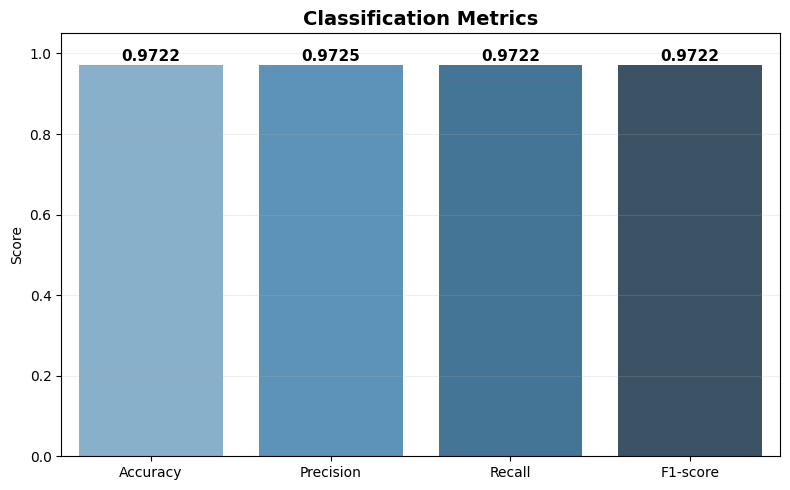

Metrics figure saved to: /content/drive/MyDrive/ResourceDACN3/artifacts/brain_mri_metrics_summary.png


In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tinh metric tong quat cho bai toan multiclass
accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average='weighted',   # phu hop khi so luong mau moi lop khong deu
    zero_division=0
)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Value": [accuracy, precision, recall, f1]
})

display(metrics_df)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=metrics_df, x="Metric", y="Value", palette="Blues_d")

for i, v in enumerate(metrics_df["Value"]):
    ax.text(i, v + 0.01, f"{v:.4f}", ha="center", fontsize=11, fontweight="bold")

plt.ylim(0, 1.05)
plt.title("Classification Metrics", fontsize=14, fontweight="bold")
plt.ylabel("Score")
plt.xlabel("")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

METRICS_PLOT_PATH = ARTIFACTS_ROOT / "brain_mri_metrics_summary.png"
plt.savefig(METRICS_PLOT_PATH, dpi=150, bbox_inches="tight")
plt.show()

print(f"Metrics figure saved to: {METRICS_PLOT_PATH}")
